#Course-Name: Machine_Learning_Pipeline

Name:Bridget Karungi

Dataset: Phish-IRIS Dataset

URL: https://www.kaggle.com/datasets/saurabhshahane/phishiris

Purpose: The dataset contains the screenshots of websites for training a computer-vision-based phishing website classification model.

Classification method: The original 15 categories will be collapsed into two classes:

Phishing: screenshots of phishing targets across 14 brand categories.

Legitimate: Other category screenshots

Data Preparation: The images are resized, normalized, and organized into training and testing datasets before the model is developed.

Original data set Bozkir, A. S., Dalgic, F. C., and Aydos, M. (2018). Phish-IRIS: Compact Visual Descriptors Based Vision for Predicting Brand of Phishing Webpages.

#Mount to Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Extract dataset

In [ ]:
import os
import zipfile

# Define the path to your dataset zip file in your Drive
zip_path = "/content/drive/MyDrive/phish_detector/phishiris.zip"
extract_dir = "/content/phishiris_dataset"
os.makedirs(extract_dir, exist_ok=True)

if not os.listdir(extract_dir):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)

print("Dataset extracted to:", extract_dir)

Dataset extracted to: /content/phishiris_dataset


#Locate train and val directories

In [ ]:
def find_split_directory(base_dir, split_name):
    matches = []

    for root, dirs, files in os.walk(base_dir):
        if os.path.basename(root).lower() == split_name.lower() and dirs:
            matches.append(root)

    if not matches:
        raise FileNotFoundError(
            f"Could not find a '{split_name}' folder containing class subfolders "
            f"inside {base_dir}"
        )

    if len(matches) > 1:
        print(f"Multiple '{split_name}' folders found:")
        for match in matches:
            print(" -", match)
        raise RuntimeError(
            f"inspect the paths above and select the correct '{split_name}' folder."
        )

    return matches[0]


train_dir = find_split_directory(extract_dir, "train")
val_dir = find_split_directory(extract_dir, "val")

print("Training directory:", train_dir)
print("Validation directory:", val_dir)

Training directory: /content/phishiris_dataset/phishIRIS_DL_Dataset/phishIRIS_DL_Dataset/train
Validation directory: /content/phishiris_dataset/phishIRIS_DL_Dataset/val


# Verify Class Consistency Across Original Splits

In [ ]:
train_classes = sorted(
    name for name in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, name))
)

val_classes = sorted(
    name for name in os.listdir(val_dir)
    if os.path.isdir(os.path.join(val_dir, name))
)

print("Training classes:", train_classes)
print("Validation classes:", val_classes)

if set(train_classes) != set(val_classes):
    raise ValueError(
        "The training and validation folders do not contain the same class folders. "
    )

Training classes: ['adobe', 'alibaba', 'amazon', 'apple', 'boa', 'chase', 'dhl', 'dropbox', 'facebook', 'linkedin', 'microsoft', 'other', 'paypal', 'wellsfargo', 'yahoo']
Validation classes: ['adobe', 'alibaba', 'amazon', 'apple', 'boa', 'chase', 'dhl', 'dropbox', 'facebook', 'linkedin', 'microsoft', 'other', 'paypal', 'wellsfargo', 'yahoo']


In [ ]:
from collections import Counter

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

def count_images_by_class(split_dir):
    counts = Counter()

    for class_name in os.listdir(split_dir):
        class_path = os.path.join(split_dir, class_name)

        if not os.path.isdir(class_path):
            continue

        image_count = 0

        for root, dirs, files in os.walk(class_path):
            image_count += sum(
                filename.lower().endswith(IMAGE_EXTENSIONS)
                for filename in files
            )

        counts[class_name] = image_count

    return counts


train_counts = count_images_by_class(train_dir)
val_counts = count_images_by_class(val_dir)

print("TRAINING IMAGE COUNTS")
for class_name, count in sorted(train_counts.items()):
    print(f"{class_name}: {count:,}")

print("\nVALIDATION IMAGE COUNTS")
for class_name, count in sorted(val_counts.items()):
    print(f"{class_name}: {count:,}")

print("\nTotal training images:", f"{sum(train_counts.values()):,}")
print("Total validation images:", f"{sum(val_counts.values()):,}")

TRAINING IMAGE COUNTS
adobe: 43
alibaba: 50
amazon: 18
apple: 49
boa: 81
chase: 74
dhl: 67
dropbox: 75
facebook: 87
linkedin: 24
microsoft: 65
other: 399
paypal: 121
wellsfargo: 89
yahoo: 70

VALIDATION IMAGE COUNTS
adobe: 27
alibaba: 26
amazon: 11
apple: 15
boa: 35
chase: 37
dhl: 42
dropbox: 40
facebook: 57
linkedin: 14
microsoft: 53
other: 998
paypal: 93
wellsfargo: 45
yahoo: 44

Total training images: 1,312
Total validation images: 1,537


In [ ]:
if "other" not in train_counts or "other" not in val_counts:
    raise ValueError(
        "Expected an 'other' class folder in both splits. "
        "Review the class names and confirm which folder represents legitimate websites."
    )

train_legitimate = train_counts["other"]
train_phishing = sum(
    count for class_name, count in train_counts.items()
    if class_name != "other"
)

val_legitimate = val_counts["other"]
val_phishing = sum(
    count for class_name, count in val_counts.items()
    if class_name != "other"
)

print("BINARY CLASS DISTRIBUTION")
print("\nTraining set")
print(f"Legitimate: {train_legitimate:,}")
print(f"Phishing:   {train_phishing:,}")

print("\nValidation set")
print(f"Legitimate: {val_legitimate:,}")
print(f"Phishing:   {val_phishing:,}")

BINARY CLASS DISTRIBUTION

Training set
Legitimate: 399
Phishing:   913

Validation set
Legitimate: 998
Phishing:   539


#Binary class visualization

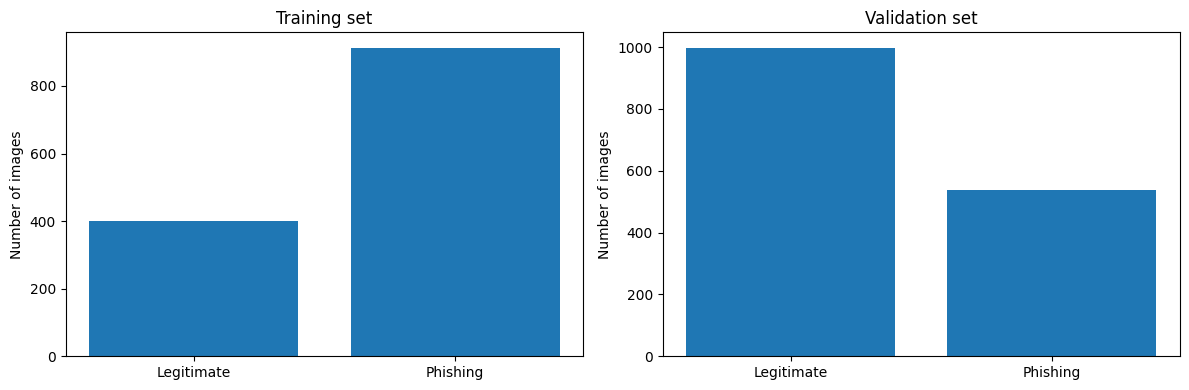

In [ ]:
import matplotlib.pyplot as plt

labels = ["Legitimate", "Phishing"]
training_values = [train_legitimate, train_phishing]
validation_values = [val_legitimate, val_phishing]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(labels, training_values)
axes[0].set_title("Training set")
axes[0].set_ylabel("Number of images")

axes[1].bar(labels, validation_values)
axes[1].set_title("Validation set")
axes[1].set_ylabel("Number of images")

plt.tight_layout()
plt.show()

#Imports


In [ ]:
import random
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# No corrupt images
ImageFile.LOAD_TRUNCATED_IMAGES = False

print('TensorFlow:', tf.__version__)
print('Image size (height, width):', IMG_SIZE)
print('Batch size:', BATCH_SIZE)

TensorFlow: 2.21.0
Image size (height, width): (224, 224)
Batch size: 32


#Data integrity and Auditing

In [ ]:
IMAGE_EXTS = (".jpg", ".jpeg", ".png")

records = []
for split_name, split_dir in (("train", train_dir), ("val", val_dir)):
    for brand in sorted(os.listdir(split_dir)):
        brand_path = os.path.join(split_dir, brand)
        if not os.path.isdir(brand_path):
            continue
        for root, _, files in os.walk(brand_path):
            for f in files:
                if f.lower().endswith(IMAGE_EXTS):
                    records.append({
                        "path": os.path.join(root, f),
                        "orig_split": split_name,
                        "brand": brand,
                        "label": 0 if brand == "other" else 1,
                    })

df = pd.DataFrame(records)

def inspect(path):
    with open(path, "rb") as fh:
        md5 = hashlib.md5(fh.read()).hexdigest()
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            return md5, im.size[0], im.size[1], im.mode, False
    except Exception:
        return md5, None, None, None, True

df[["md5", "width", "height", "mode", "corrupt"]] = df["path"].apply(
    lambda p: pd.Series(inspect(p))
)

print("Total images:", len(df))
print("Corrupt images:", int(df["corrupt"].sum()))
print("\nColour modes:\n", df["mode"].value_counts())
print("\nSize stats:\n", df[["width", "height"]].describe().round(0))

dup_groups = df[df.duplicated("md5", keep=False)].groupby("md5")
print("\nDuplicate groups:", dup_groups.ngroups)
print("Images involved in duplicates:", int(df.duplicated("md5", keep=False).sum()))

cross = dup_groups.filter(lambda g: g["orig_split"].nunique() > 1)
print("Images duplicated across train and val:", len(cross))

conflict = dup_groups.filter(lambda g: g["label"].nunique() > 1)
print("Duplicates with conflicting labels:", len(conflict))

df.to_csv("/content/drive/MyDrive/phish_detector/audit.csv", index=False)

Total images: 2849
Corrupt images: 0

Colour modes:
 mode
RGB     2062
RGBA     787
Name: count, dtype: int64

Size stats:
         width  height
count  2849.0  2849.0
mean   1238.0   959.0
std     310.0   172.0
min     505.0   318.0
25%    1024.0   855.0
50%    1024.0  1012.0
75%    1280.0  1024.0
max    2353.0  2856.0

Duplicate groups: 320
Images involved in duplicates: 720
Images duplicated across train and val: 452
Duplicates with conflicting labels: 0


#Deduplication

In [ ]:
df_clean = (
    df.sort_values("path")
      .drop_duplicates(subset="md5", keep="first")
      .reset_index(drop=True)
)

print("Before:", len(df), "| After:", len(df_clean))
print("\nBinary label counts (0=legitimate, 1=phishing):")
print(df_clean["label"].value_counts().sort_index())
print("\nPhishing share: {:.1%}".format(df_clean["label"].mean()))
print("\nBrand counts:")
print(df_clean["brand"].value_counts())

df_clean.to_csv("/content/drive/MyDrive/phish_detector/clean.csv", index=False)

Before: 2849 | After: 2449

Binary label counts (0=legitimate, 1=phishing):
label
0    1370
1    1079
Name: count, dtype: int64

Phishing share: 44.1%

Brand counts:
brand
other         1370
paypal         175
facebook       110
microsoft       91
wellsfargo      89
chase           84
boa             82
dropbox         80
dhl             78
yahoo           77
adobe           56
alibaba         55
apple           48
linkedin        30
amazon          24
Name: count, dtype: int64


Extracting image features across 2449 unique images...


/tmp/ipykernel_1173/3736378513.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


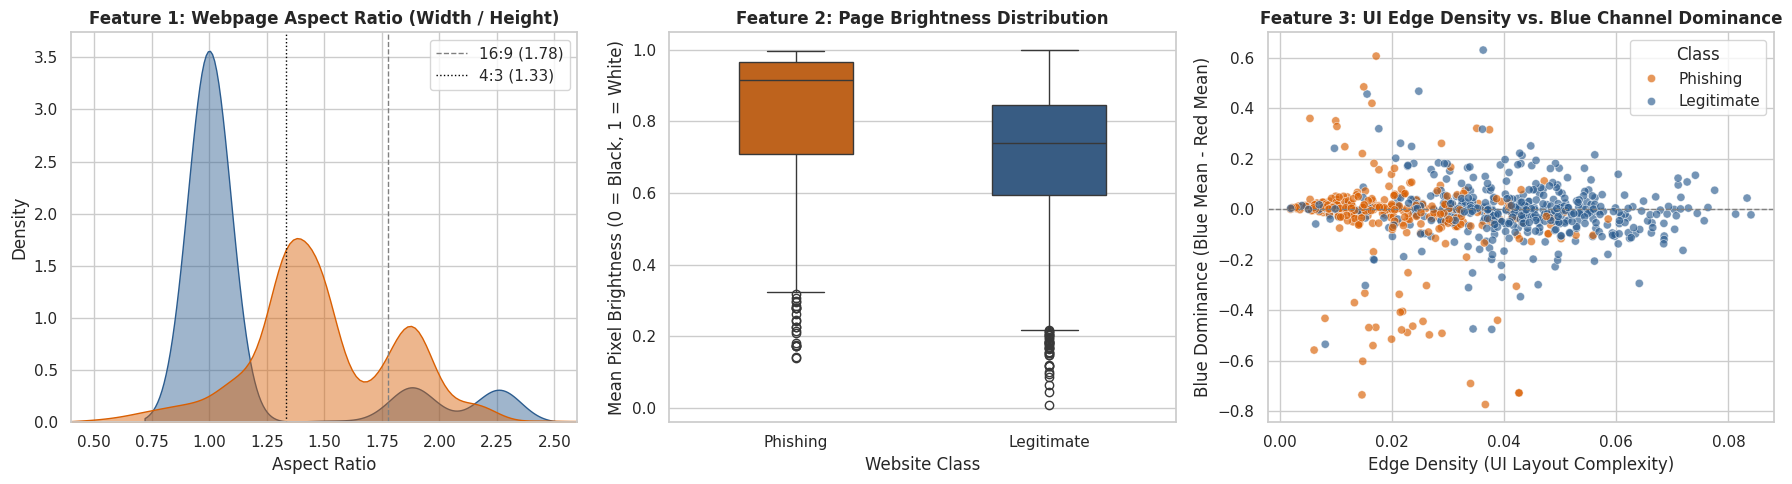


MEAN FEATURE VALUES BY CLASS:
            aspect_ratio  brightness  contrast  blue_dominance  edge_density
class_name                                                                  
Legitimate        1.1721      0.7006    0.2652         -0.0021        0.0396
Phishing          1.4965      0.8255    0.1918         -0.0218        0.0197


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Ensure clean dataframe is loaded
if "df_clean" not in locals():
    df_clean = pd.read_csv("/content/drive/MyDrive/phish_detector/clean.csv")

df_feat = df_clean.copy()
df_feat["class_name"] = df_feat["label"].map({0: "Legitimate", 1: "Phishing"})

# Feature 1 (Metadata): Aspect Ratio & Image Area
df_feat["aspect_ratio"] = df_feat["width"] / df_feat["height"]
df_feat["megapixels"] = (df_feat["width"] * df_feat["height"]) / 1e6

# Extract pixel-level features
def extract_pixel_features(path):
    with Image.open(path) as im:
        rgb = im.convert("RGB").resize((128, 128))
        arr = np.asarray(rgb, dtype=np.float32) / 255.0

    # Feature 2: Brightness
    brightness = arr.mean()
    contrast = arr.std()

    # Feature 3: Mean RGB Channel Intensities
    r_mean, g_mean, b_mean = arr[:, :, 0].mean(), arr[:, :, 1].mean(), arr[:, :, 2].mean()
    blue_dominance = b_mean - r_mean

    # Feature 4: Visual Complexity
    gray = arr.mean(axis=2)
    grad_x = np.abs(np.diff(gray, axis=1)).mean()
    grad_y = np.abs(np.diff(gray, axis=0)).mean()
    edge_density = (grad_x + grad_y) / 2.0

    return brightness, contrast, r_mean, g_mean, b_mean, blue_dominance, edge_density

print("Extracting image features across", len(df_feat), "unique images...")
pixel_cols = [
    "brightness", "contrast", "r_mean", "g_mean", "b_mean",
    "blue_dominance", "edge_density"
]
df_feat[pixel_cols] = df_feat["path"].apply(lambda p: pd.Series(extract_pixel_features(p)))

# Save features
df_feat.to_csv("/content/drive/MyDrive/phish_detector/features.csv", index=False)

# PLOT 3 FEATURE VISUALIZATIONS
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = {"Legitimate": "#2b5c8f", "Phishing": "#d95f02"}

# Visualization 1
sns.kdeplot(
    data=df_feat, x="aspect_ratio", hue="class_name",
    fill=True, common_norm=False, palette=palette, alpha=0.45, ax=axes[0]
)
axes[0].axvline(16/9, color="gray", linestyle="--", linewidth=1, label="16:9 (1.78)")
axes[0].axvline(4/3, color="black", linestyle=":", linewidth=1, label="4:3 (1.33)")
axes[0].set_xlim(0.4, 2.6)
axes[0].set_title("Feature 1: Webpage Aspect Ratio (Width / Height)", fontweight="bold")
axes[0].set_xlabel("Aspect Ratio")
axes[0].set_ylabel("Density")
axes[0].legend()

# Visualization 2
sns.boxplot(
    data=df_feat, x="class_name", y="brightness",
    palette=palette, width=0.45, ax=axes[1]
)
axes[1].set_title("Feature 2: Page Brightness Distribution", fontweight="bold")
axes[1].set_xlabel("Website Class")
axes[1].set_ylabel("Mean Pixel Brightness (0 = Black, 1 = White)")

# Visualization 3
sns.scatterplot(
    data=df_feat.sample(min(800, len(df_feat)), random_state=42),
    x="edge_density", y="blue_dominance", hue="class_name",
    palette=palette, alpha=0.65, s=35, ax=axes[2]
)
axes[2].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[2].set_title("Feature 3: UI Edge Density vs. Blue Channel Dominance", fontweight="bold")
axes[2].set_xlabel("Edge Density (UI Layout Complexity)")
axes[2].set_ylabel("Blue Dominance (Blue Mean - Red Mean)")
axes[2].legend(title="Class")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/phish_detector/feature_visualizations.png", dpi=150)
plt.show()

# summary statistics
print("\nMEAN FEATURE VALUES BY CLASS:")
print(df_feat.groupby("class_name")[["aspect_ratio", "brightness", "contrast", "blue_dominance", "edge_density"]].mean().round(4))

### Feature Visualization Interpretations

1. Webpage Aspect Ratio (`width / height`): The phishing screenshots show a larger mean aspect ratio (**1.4965** for phishing and 1.1721 for legitimate sites) due to compact login modals with only one viewport for phishing websites as compared to larger legitimate pages having multiple sections.

2. Distribution of Page Brightness: Phishing pages have a higher mean brightness value of pixels (**0.8255** for phishing and 0.7006 for legitimate pages), which is mainly because of the high-luminance white backgrounds of phishing sites in order to make the credentials form more noticeable.

3. Edge Density of UI and Blue Dominance: There is a distinction between the edge density of phishing pages (half of which is 0.0197) and that of legitimate websites (half of which is 0.0396).

#Data Splitting

train n=1714  phishing share=44.0%
val   n= 367  phishing share=44.1%
test  n= 368  phishing share=44.0%
Class weights: {0: 0.8936392075078207, 1: 1.1350993377483443}
Batch: (32, 224, 224, 3) <dtype: 'float32'> | pixel range: 0.0 - 255.0


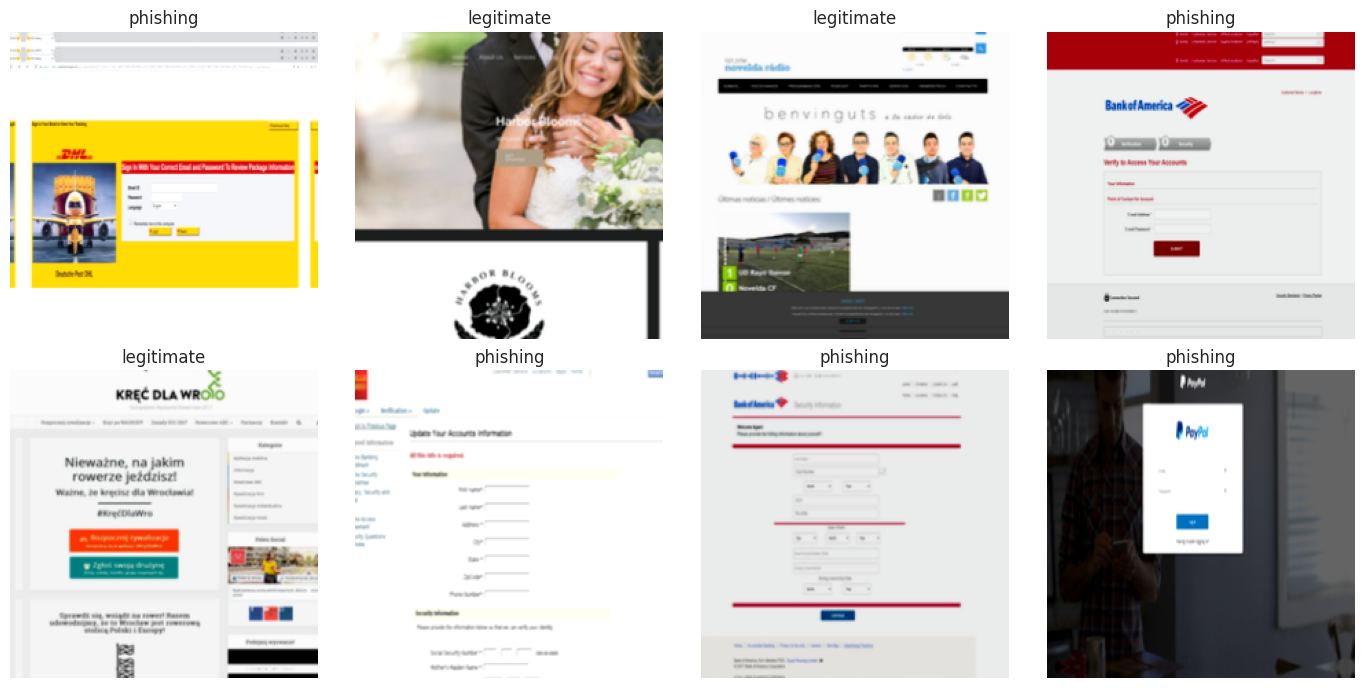

In [ ]:
PROC_DIR = "/content/processed"
LABEL_NAMES = {0: "legitimate", 1: "phishing"}

def preprocess_image(src, size=IMG_SIZE):
    """Open an image path/file object -> RGB PIL image at `size` (h, w)."""
    im = Image.open(src)
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        bg = Image.new("RGB", im.size, (255, 255, 255))
        bg.paste(im, mask=im.split()[-1])
        im = bg
    else:
        im = im.convert("RGB")
    return im.resize((size[1], size[0]), Image.LANCZOS)

# stratified 70/15/15 split
train_df, temp_df = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean["brand"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["brand"], random_state=SEED)

# write preprocessed images to disk
def export_split(split_df, split_name):
    split_df = split_df.copy()
    new_paths = []
    for _, row in split_df.iterrows():
        out_dir = os.path.join(PROC_DIR, split_name, LABEL_NAMES[row["label"]])
        os.makedirs(out_dir, exist_ok=True)
        out_path = os.path.join(out_dir, row["md5"] + ".png")
        if not os.path.exists(out_path):
            preprocess_image(row["path"]).save(out_path)
        new_paths.append(out_path)
    split_df["proc_path"] = new_paths
    return split_df

train_df = export_split(train_df, "train")
val_df   = export_split(val_df, "val")
test_df  = export_split(test_df, "test")

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} n={len(d):4d}  phishing share={d['label'].mean():.1%}")

pd.concat([train_df.assign(split="train"), val_df.assign(split="val"),
           test_df.assign(split="test")]).to_csv(
    "/content/drive/MyDrive/phish_detector/splits.csv", index=False)

# class weights (train only)
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["label"])
class_weights = {0: float(cw[0]), 1: float(cw[1])}
print("Class weights:", class_weights)

# tf.data pipeline
def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img.set_shape([*IMG_SIZE, 3])
    return img, tf.cast(label, tf.float32)

augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.1),
], name="augmentation")

def make_ds(split_df, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (split_df["proc_path"].values, split_df["label"].values))
    if training:
        ds = ds.shuffle(len(split_df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

# shapes + a visual sample
xb, yb = next(iter(train_ds))
print("Batch:", xb.shape, xb.dtype, "| pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, lab in zip(axes.ravel(), xb[:8], yb[:8]):
    ax.imshow(tf.clip_by_value(img, 0, 255).numpy().astype("uint8"))
    ax.set_title(LABEL_NAMES[int(lab)])
    ax.axis("off")
plt.tight_layout(); plt.show()

#Baseline custom CNN

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 250,209 (977.38 KB)

 Trainable params: 249,505 (974.63 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 55s 644ms/step - accuracy: 0.7270 - auc: 0.7893 - loss: 0.6028 - precision: 0.6756 - recall: 0.7311 - val_accuracy: 0.4414 - val_auc: 0.7693 - val_loss: 0.9821 - val_precision: 0.4414 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 17s 299ms/step - accuracy: 0.7509 - auc: 0.8282 - loss: 0.5493 - precision: 0.6966 - recall: 0.7695 - val_accuracy: 0.4414 - val_auc: 0.7908 - val_loss: 1.1321 - val_precision: 0.4414 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 16s 292ms/step - accuracy: 0.7608 - auc: 0.8374 - loss: 0.5361 - precision: 0.7122 - recall: 0.7669 - val_accuracy: 0.4414 - val_auc: 0.8025 - val_loss: 1.1726 - val_precision: 0.4414 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 16s 297ms/step - accuracy: 0.7690 - auc: 0.8438 - loss: 0.5319 - precision: 0.7139 - recall: 0.7934 - val_accuracy: 0.4496 - val_auc: 0.8828 - val_loss: 0.9588 -

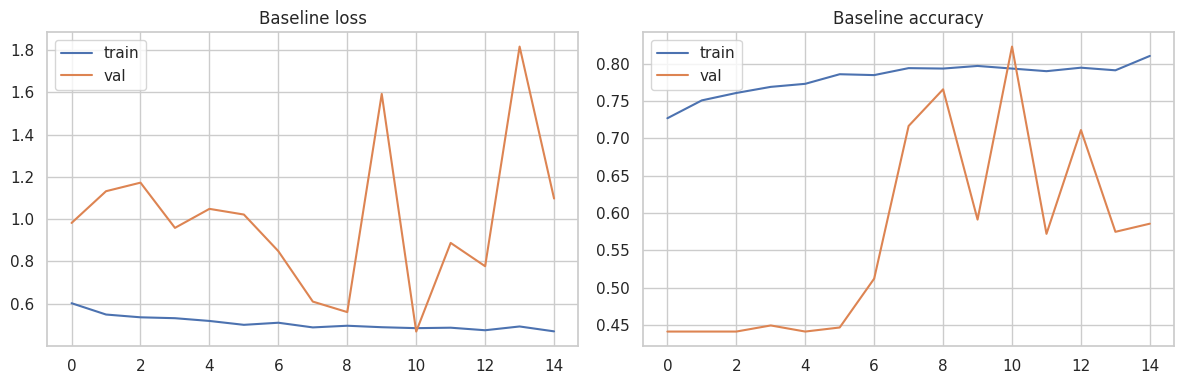

              precision    recall  f1-score   support

  legitimate      0.893     0.776     0.830       205
    phishing      0.757     0.883     0.815       162

    accuracy                          0.823       367
   macro avg      0.825     0.829     0.823       367
weighted avg      0.833     0.823     0.823       367



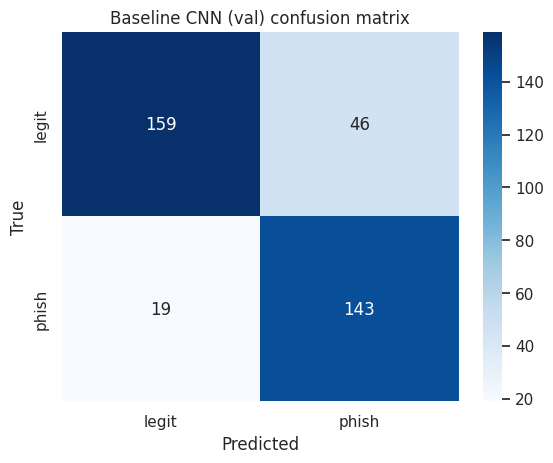

{'model': 'Baseline CNN (val)', 'accuracy': 0.8228882833787466, 'precision': 0.7566137566137566, 'recall': 0.8827160493827161, 'f1': 0.8148148148148148, 'auc': np.float64(0.9078289671785607)}


In [ ]:
from tensorflow.keras import layers, models, regularizers, callbacks
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score,
                             accuracy_score, roc_auc_score)

MODEL_DIR = "/content/drive/MyDrive/phish_detector/models"
os.makedirs(MODEL_DIR, exist_ok=True)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def build_baseline():
    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 255)(inp)
    for f in (32, 64, 128, 128):
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu",
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inp, out, name="baseline_cnn")

baseline = build_baseline()
baseline.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.AUC(name="auc")])
baseline.summary()

cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=6,
                            restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                min_lr=1e-6),
    callbacks.ModelCheckpoint(f"{MODEL_DIR}/baseline_cnn.keras",
                              monitor="val_loss", save_best_only=True),
]

hist_base = baseline.fit(train_ds, validation_data=val_ds, epochs=15,
                         class_weight=class_weights, callbacks=cbs)

#  reusable evaluation
def evaluate_model(model, ds, name="model", threshold=0.5):
    y_true = np.concatenate([y.numpy() for _, y in ds]).astype(int)
    y_prob = model.predict(ds, verbose=0).ravel()
    y_pred = (y_prob >= threshold).astype(int)
    res = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob),
    }
    print(classification_report(y_true, y_pred,
          target_names=["legitimate", "phishing"], digits=3))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["legit", "phish"], yticklabels=["legit", "phish"])
    plt.title(f"{name} confusion matrix"); plt.ylabel("True"); plt.xlabel("Predicted")
    plt.show()
    return res

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history["loss"], label="train"); ax[0].plot(h.history["val_loss"], label="val")
    ax[0].set_title(f"{title} loss"); ax[0].legend()
    ax[1].plot(h.history["accuracy"], label="train"); ax[1].plot(h.history["val_accuracy"], label="val")
    ax[1].set_title(f"{title} accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(hist_base, "Baseline")
base_val = evaluate_model(baseline, val_ds, "Baseline CNN (val)")
print(base_val)

#Pretrained Model with Regularization (MobileNetV2 + Augmentation + Dropout)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models


# Load Pretrained MobileNetV2 Backbone
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

# Build Custom Classification Head with L2 Regularization & Dropout
inputs = tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(1e-4)
)(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name="PhishIRIS_MobileNetV2")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "PhishIRIS_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,201 (9.26 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

#MobileNetV2(Frozen Backbone)

In [ ]:
PHASE1_EPOCHS = 8
base_model.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)

early_stop_p1 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

print("Starting Phase 1: Feature Extraction...")
history_p1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=PHASE1_EPOCHS,
    class_weight=class_weights,
    callbacks=[early_stop_p1],
)

Starting Phase 1: Feature Extraction...
Epoch 1/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 81s 989ms/step - accuracy: 0.7695 - auc: 0.8385 - loss: 0.6114 - precision: 0.7350 - recall: 0.7457 - val_accuracy: 0.8392 - val_auc: 0.9190 - val_loss: 0.3997 - val_precision: 0.8503 - val_recall: 0.7716
Epoch 2/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 17s 312ms/step - accuracy: 0.8536 - auc: 0.9182 - loss: 0.3964 - precision: 0.8111 - recall: 0.8702 - val_accuracy: 0.8747 - val_auc: 0.9304 - val_loss: 0.3559 - val_precision: 0.8580 - val_recall: 0.8580
Epoch 3/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 20s 309ms/step - accuracy: 0.8670 - auc: 0.9347 - loss: 0.3573 - precision: 0.8265 - recall: 0.8834 - val_accuracy: 0.8719 - val_auc: 0.9349 - val_loss: 0.3444 - val_precision: 0.8662 - val_recall: 0.8395
Epoch 4/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 17s 311ms/step - accuracy: 0.8862 - auc: 0.9558 - loss: 0.2885 - precision: 0.8448 - recall: 0.9086 - val_accuracy: 0.8828 - val_auc: 0.9451 - val_loss: 0.3168 - val_precision: 0.8563 - val_recall:

In [ ]:
PHASE2_EPOCHS = 10
base_model.trainable = True

# Fine-tune top 30% of MobileNetV2 layers
fine_tune_at = int(len(base_model.layers) * 0.7)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)

callbacks_p2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7
    ),
]
history_p2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=PHASE2_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_p2,
)

# Save the trained base model
MODEL_SAVE_PATH = "/content/drive/MyDrive/phish_detector/phishiris_model.h5"
model.save(MODEL_SAVE_PATH)
print("Model saved successfully to:", MODEL_SAVE_PATH)

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 66s 690ms/step - accuracy: 0.7940 - auc: 0.8655 - loss: 0.5416 - precision: 0.7680 - recall: 0.7629 - val_accuracy: 0.8965 - val_auc: 0.9499 - val_loss: 0.3103 - val_precision: 0.8483 - val_recall: 0.9321 - learning_rate: 1.0000e-05
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 18s 321ms/step - accuracy: 0.8191 - auc: 0.8978 - loss: 0.4543 - precision: 0.7799 - recall: 0.8212 - val_accuracy: 0.8937 - val_auc: 0.9509 - val_loss: 0.3069 - val_precision: 0.8475 - val_recall: 0.9259 - learning_rate: 1.0000e-05
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 19s 305ms/step - accuracy: 0.8355 - auc: 0.9102 - loss: 0.4228 - precision: 0.7975 - recall: 0.8397 - val_accuracy: 0.8910 - val_auc: 0.9526 - val_loss: 0.3082 - val_precision: 0.8506 - val_recall: 0.9136 - learning_rate: 1.0000e-05
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 17s 300ms/step - accuracy: 0.8576 - auc: 0.9270 - loss: 0.3730 - precision: 0.8158 - recall: 0.8742 - val_accuracy: 0.8883 - val_auc: 0.9535 - val_lo

Model saved successfully to: /content/drive/MyDrive/phish_detector/phishiris_model.h5


FINAL TEST SET EVALUATION METRICS
Test Loss:      0.3691
Accuracy:       0.8668
Precision:      0.8087
Recall:         0.9136
F1-Score:       0.8580
ROC-AUC Score:  0.9379

Detailed Classification Report:

                precision    recall  f1-score   support

Legitimate (0)       0.92      0.83      0.87       206
  Phishing (1)       0.81      0.91      0.86       162

      accuracy                           0.87       368
     macro avg       0.87      0.87      0.87       368
  weighted avg       0.87      0.87      0.87       368



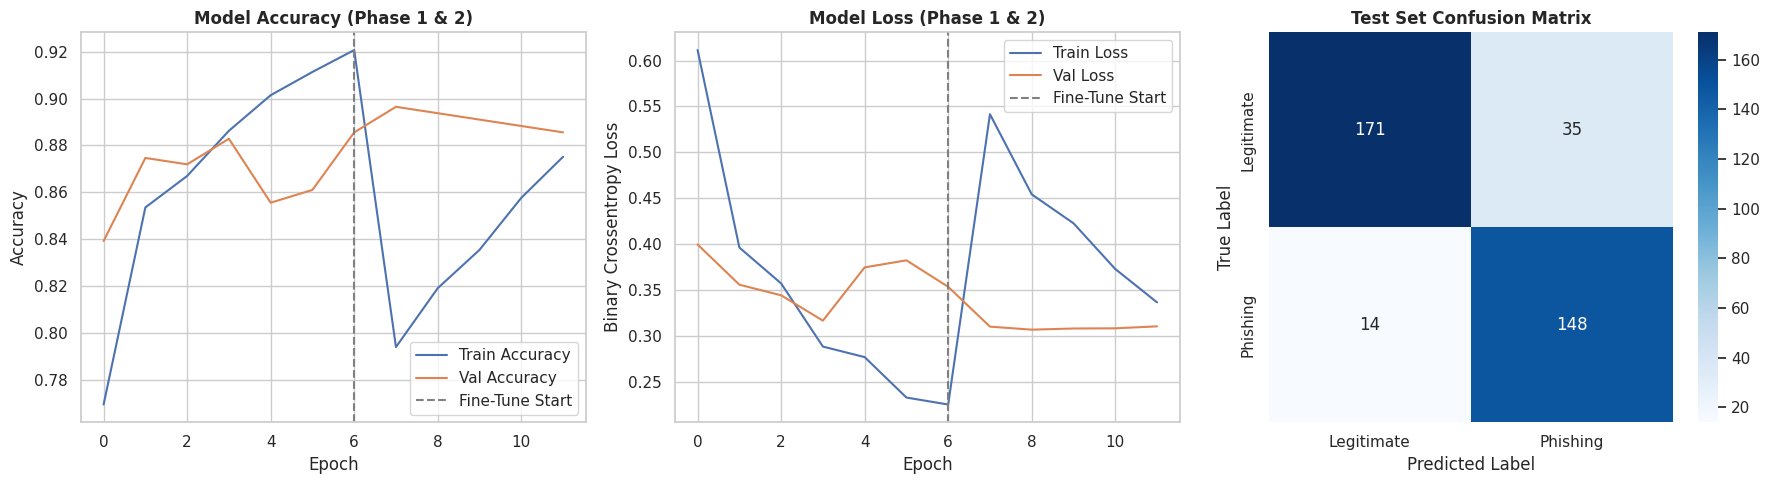

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# 1. Evaluate Keras
test_results = model.evaluate(test_ds, verbose=0)
test_loss = test_results[0]

# 2. Gather ground-truth labels and predicted probabilities from test_ds
y_true = []
y_probs = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0).ravel()
    y_probs.extend(preds)
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true, dtype=int)
y_probs = np.array(y_probs)
y_pred = (y_probs >= 0.5).astype(int)

# 3. Compute all evaluation metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_probs)

print("=" * 45)
print("FINAL TEST SET EVALUATION METRICS")
print("=" * 45)
print(f"Test Loss:      {test_loss:.4f}")
print(f"Accuracy:       {acc:.4f}")
print(f"Precision:      {prec:.4f}")
print(f"Recall:         {rec:.4f}")
print(f"F1-Score:       {f1:.4f}")
print(f"ROC-AUC Score:  {auc:.4f}")
print("=" * 45)
print("\nDetailed Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=["Legitimate (0)", "Phishing (1)"]))

# 4. Plot Training History (Phase 1 + Phase 2) & Confusion Matrix
acc_hist = history_p1.history["accuracy"] + history_p2.history["accuracy"]
val_acc_hist = history_p1.history["val_accuracy"] + history_p2.history["val_accuracy"]
loss_hist = history_p1.history["loss"] + history_p2.history["loss"]
val_loss_hist = history_p1.history["val_loss"] + history_p2.history["val_loss"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Accuracy Curve
axes[0].plot(acc_hist, label="Train Accuracy")
axes[0].plot(val_acc_hist, label="Val Accuracy")
axes[0].axvline(len(history_p1.history["accuracy"]) - 1, color="gray", linestyle="--", label="Fine-Tune Start")
axes[0].set_title("Model Accuracy (Phase 1 & 2)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss Curve
axes[1].plot(loss_hist, label="Train Loss")
axes[1].plot(val_loss_hist, label="Val Loss")
axes[1].axvline(len(history_p1.history["loss"]) - 1, color="gray", linestyle="--", label="Fine-Tune Start")
axes[1].set_title("Model Loss (Phase 1 & 2)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Crossentropy Loss")
axes[1].legend()

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"],
    ax=axes[2]
)
axes[2].set_title("Test Set Confusion Matrix", fontweight="bold")
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/phish_detector/evaluation_metrics.png", dpi=150)
plt.show()

 threshold  precision  recall    f1    f2
      0.20      0.803   0.957 0.873 0.922
      0.25      0.820   0.957 0.883 0.926
      0.30      0.832   0.951 0.888 0.924
      0.35      0.842   0.951 0.893 0.927
      0.40      0.845   0.944 0.892 0.923
      0.45      0.844   0.938 0.889 0.918
      0.50      0.847   0.926 0.885 0.909
      0.55      0.851   0.920 0.884 0.905
      0.60      0.869   0.901 0.885 0.895
      0.65      0.888   0.877 0.882 0.879
      0.70      0.886   0.864 0.875 0.868
      0.75      0.900   0.833 0.865 0.846
      0.80      0.912   0.827 0.867 0.843

Chosen threshold: 0.35
              precision    recall  f1-score   support

  legitimate      0.924     0.830     0.875       206
    phishing      0.809     0.914     0.858       162

    accuracy                          0.867       368
   macro avg      0.867     0.872     0.866       368
weighted avg      0.873     0.867     0.867       368



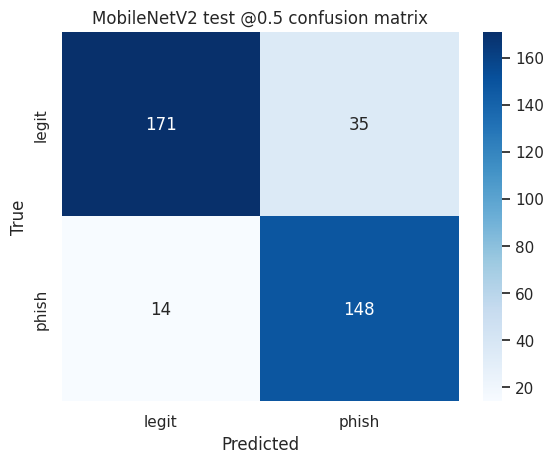

              precision    recall  f1-score   support

  legitimate      0.927     0.801     0.859       206
    phishing      0.784     0.920     0.847       162

    accuracy                          0.853       368
   macro avg      0.856     0.860     0.853       368
weighted avg      0.864     0.853     0.854       368



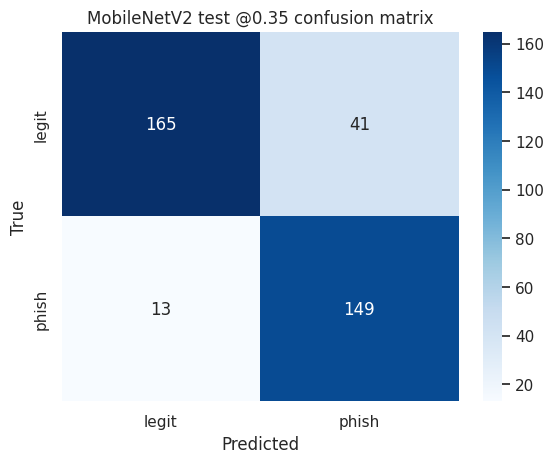

                 model  accuracy  precision  recall    f1   auc
 MobileNetV2 test @0.5     0.867      0.809   0.914 0.858 0.938
MobileNetV2 test @0.35     0.853      0.784   0.920 0.847 0.938


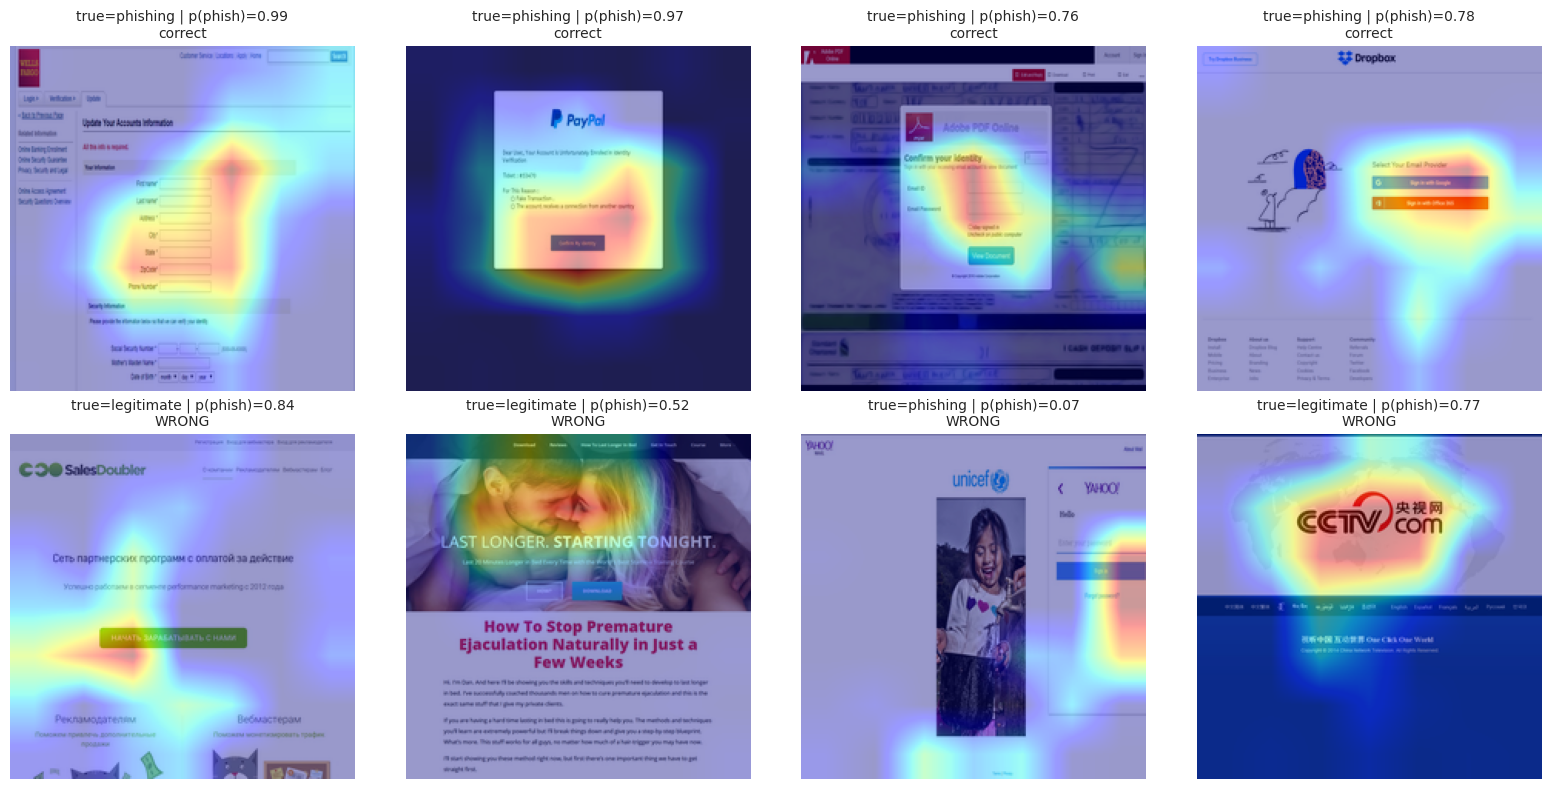

In [ ]:

import json
from sklearn.metrics import fbeta_score

def get_probs(model, ds):
    y = np.concatenate([b[1].numpy() for b in ds]).astype(int)
    p = model.predict(ds, verbose=0).ravel()
    return y, p

# choose threshold on VALIDATION only
yv, pv = get_probs(model, val_ds)
rows = []
for t in np.arange(0.20, 0.81, 0.05):
    yp = (pv >= t).astype(int)
    rows.append({"threshold": round(float(t), 2),
                 "precision": precision_score(yv, yp),
                 "recall": recall_score(yv, yp),
                 "f1": f1_score(yv, yp),
                 "f2": fbeta_score(yv, yp, beta=2)})
thr_df = pd.DataFrame(rows).round(3)
print(thr_df.to_string(index=False))
best_t = float(thr_df.loc[thr_df["f2"].idxmax(), "threshold"])
print("\nChosen threshold:", best_t)

#  ONE evaluation on the TEST set
test_default = evaluate_model(model, test_ds, "MobileNetV2 test @0.5", threshold=0.5)
test_tuned   = evaluate_model(model, test_ds, f"MobileNetV2 test @{best_t}", threshold=best_t)
print(pd.DataFrame([test_default, test_tuned]).round(3).to_string(index=False))

# save model config for the API / retraining
config = {"img_size": list(IMG_SIZE), "threshold": best_t,
          "labels": {"0": "legitimate", "1": "phishing"}}
with open(f"{MODEL_DIR}/model_config.json", "w") as f:
    json.dump(config, f, indent=2)


#  Grad-CAM
head = model.layers[model.layers.index(base_model) + 1:]

def gradcam(img):
    x = tf.keras.applications.mobilenet_v2.preprocess_input(tf.expand_dims(img, 0))
    with tf.GradientTape() as tape:
        conv = base_model(x, training=False)
        tape.watch(conv)
        y = conv
        for l in head:
            y = l(y, training=False)
        score = y[:, 0]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), float(score[0])

yt, pt = get_probs(model, test_ds)
pred = (pt >= best_t).astype(int)
wrong = np.where(pred != yt)[0][:4]
right = np.where((pred == yt) & (yt == 1))[0][:4]
picks = list(right) + list(wrong)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), picks):
    img = np.array(Image.open(test_df.iloc[i]["proc_path"]).convert("RGB")).astype("float32")
    cam, prob = gradcam(img)
    cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]
    ax.imshow(img.astype("uint8")); ax.imshow(cam, cmap="jet", alpha=0.4)
    ok = "correct" if pred[i] == yt[i] else "WRONG"
    ax.set_title(f"true={LABEL_NAMES[yt[i]]} | p(phish)={prob:.2f}\n{ok}", fontsize=10)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
print(model.evaluate(test_ds))
model.save("/content/drive/MyDrive/phish_detector/phishiris_model.keras")
model.save_weights("/content/drive/MyDrive/phish_detector/phishiris.weights.h5")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.8668 - auc: 0.9379 - loss: 0.3691 - precision: 0.8087 - recall: 0.9136
[0.3690601885318756, 0.866847813129425, 0.8087431788444519, 0.9135802388191223, 0.9379421472549438]
